# Mapping the Cosmic Web: *A Large-Scale Structure Analysis of SDSS Galaxies*



---

## **Objective:**

This project aims to study the large-scale structure of the Universe using spectroscopic galaxy observations from the Sloan Digital Sky Survey (SDSS). The analysis begins with preprocessing and quality assessment of the dataset, followed by the computation of cosmological comoving distances using the Flat ΛCDM model. Through exploratory data analysis, including redshift distributions, sky coverage, wedge diagrams, three-dimensional visualizations, and galaxy density estimation, the project investigates how galaxies are distributed across cosmological scales. The findings are interpreted in terms of the cosmic web, observational selection effects, and the cosmological principle, demonstrating how large astronomical surveys provide insights into the evolution and structure of the Universe.

---



> AUTHOR: Shashwat Srivastava

> EMAIL: astroshashwatsri[at]gmail[dot]com


## Dataset Description

This project utilizes spectroscopic galaxy observations from the Sloan Digital Sky Survey (SDSS), one of the largest astronomical sky surveys conducted to map the Universe.

The data were obtained from the SDSS SkyServer SQL Search Interface:

Website: https://skyserver.sdss.org/dr18/SearchTools/sql

The dataset was downloaded as a CSV file after executing a custom SQL query to retrieve only galaxies with reliable spectroscopic redshift measurements.

ACCESS DATASET HERE for UPLOAD: https://drive.google.com/drive/folders/1RdZ3iFVmd2B9eREImVRSBP70f4NzmLfd?usp=sharing
---

```

SELECT TOP 100000
    p.objid,
    p.ra,
    p.dec,
    s.z,
    s.zErr
FROM SpecObj AS s
JOIN PhotoObj AS p
ON s.bestObjID = p.objID
WHERE
    s.class='GALAXY'
    AND s.zWarning = 0

```
---

| Parameter                | Unit          | Description                                                                                                     |
| ------------------------ | ------------- | --------------------------------------------------------------------------------------------------------------- |
| **objID**                | —             | Unique identifier assigned to each astronomical object in the SDSS database.                                    |
| **RA (Right Ascension)** | Degrees (°)   | Celestial longitude measured eastward along the celestial equator, specifying the object's position on the sky. |
| **Dec (Declination)**    | Degrees (°)   | Celestial latitude measured north or south of the celestial equator.                                            |
| **z (Redshift)**         | Dimensionless | Spectroscopically measured cosmological redshift used to estimate the galaxy's distance.                        |
| **zErr**                 | Dimensionless | Estimated uncertainty in the measured redshift.                                                                 |


In [ ]:
# Importing the Dataset downloaded in csv format to Colab Notebook

from google.colab import files

uploaded = files.upload()



Saving SDSS_data_galaxies.csv to SDSS_data_galaxies.csv


In [ ]:
import warnings
warnings.filterwarnings("ignore")


In [ ]:
import pandas as pd

df = pd.read_csv("SDSS_data_galaxies.csv")


## Data Cleaning / Preprocessing




In [ ]:
df.head() # To check data structure

,objid,ra,dec,z,zErr
0,1.237650e+18,212.049238,-1.191286,0.378565,0.000067
1,1.237650e+18,204.973433,-0.726887,0.499448,0.000121
2,1.237650e+18,211.904634,-0.764767,0.104625,0.000006
3,1.237650e+18,205.492243,-0.286499,0.105161,0.000021
4,1.237650e+18,207.323660,-0.387463,0.509097,0.000082


In [ ]:
df.info()  # To check Column's Data Type and Number of entries

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   objid   100000 non-null  float64
 1   ra      100000 non-null  float64
 2   dec     100000 non-null  float64
 3   z       100000 non-null  float64
 4   zErr    100000 non-null  float64
dtypes: float64(5)
memory usage: 3.8 MB


In [ ]:
df.describe() # For a at-a-glance data stats

,objid,ra,dec,z,zErr
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.237650e+18,160.866525,18.778555,0.352437,0.000438
std,5.534748e+05,56.094713,25.815099,0.218468,0.060510
min,1.237650e+18,5.715961,-8.731240,-0.004713,-6.000000
25%,1.237650e+18,131.237978,-0.671468,0.126766,0.000024
50%,1.237650e+18,164.699444,0.663589,0.377598,0.000077
75%,1.237650e+18,199.276828,47.774781,0.536006,0.000143
max,1.237650e+18,348.902530,68.535721,1.652483,9.393559


In [ ]:
df.isnull().sum() # Missing Values

,0
objid,0
ra,0
dec,0
z,0
zErr,0


In [ ]:
df.duplicated().sum() # To check duplicate galaxies

np.int64(0)

In [ ]:
df = df[
    (df["ra"] >= 0) &
    (df["ra"] < 360) &
    (df["dec"] >= -90) &
    (df["dec"] <= 90) &
    (df["z"] > 0)
]

The SDSS spectroscopic dataset was inspected for missing values, duplicate records, and invalid coordinate or redshift entries. No Rows contained missing values in Right Ascension (RA), Declination (Dec), or redshift (z). Coordinate ranges were validated (RA: 0°–360°, Dec: −90° to +90°, z > 0).

Since SDSS provides calibrated observational data, no feature scaling or normalization was required before calculating comoving distances and constructing the three-dimensional galaxy distribution.

In [ ]:
from astropy.cosmology import FlatLambdaCDM

cosmo = FlatLambdaCDM(
    H0=68.17,
    Om0=0.3027 #Ref-1
)

df["distance"] = cosmo.comoving_distance(df["z"]).value

In [ ]:
import numpy as np

# Convert RA and Dec from degrees to radians
ra_rad = np.deg2rad(df["ra"])
dec_rad = np.deg2rad(df["dec"])

# Comoving distance (Mpc)
r = df["distance"]

# Cartesian coordinates
df["x_coord"] = r * np.cos(dec_rad) * np.cos(ra_rad)
df["y_coord"] = r * np.cos(dec_rad) * np.sin(ra_rad)
df["z_coord"] = r * np.sin(dec_rad)

In [ ]:
# Verifying if the conversion is correct.

df["r_check"] = np.sqrt(df["x_coord"]**2 + df["y_coord"]**2 + df["z_coord"]**2)

print(df[["distance", "r_check"]].head())

      distance      r_check
0  1515.236174  1515.236174
1  1935.662758  1935.662758
2   448.968282   448.968282
3   451.212578   451.212578
4  1967.943547  1967.943547


Redshift is not a direct measure of physical distance because the expansion rate of the Universe changes with cosmic time. Therefore, comoving distance was computed using the Flat ΛCDM cosmological model implemented in Astropy with H₀ = 70 km s⁻¹ Mpc⁻¹ and Ωₘ = 0.3.

---
The comoving distance is given by

$$
D_C(z) = c \int_{0}^{z} \frac{dz'}{H(z')}
$$

where, for a flat $\Lambda$ CDM cosmology,

$$
H(z) = H_0 \sqrt{\Omega_m(1+z)^3 + \Omega_\Lambda}.
$$

---
Then the Right Ascension (RA) in radians and Declination(DEC) in radians is converted into cartesian coordiantes (x,y,z) using

$$x = D_c cos(δ)cos(α)$$
$$y = D_c cos(δ)sin(α)$$
$$z = D_c sin(δ)$$

where $D_c$ is Comoving Distance in MPc, $α$ is RA and $δ$ is DEC.

## Exploratory Data Analysis (EDA)

The aim of EDA is to understand the statistical and physical properties of the SDSS galaxy sample before performing three-dimensional reconstruction of the large-scale structure of the Universe. The analysis helps identify observational biases, verify data quality, study the distribution of galaxies in celestial coordinates and redshift space, and ensure the dataset is suitable for cosmic web visualization.

### 1. Distribution of Redshift $z$

In [ ]:
#import numpy as np ( already imported)
import matplotlib.pyplot as plt

In [ ]:
redshift = df["z"]

In [ ]:
bin_edges = np.arange(0, redshift.max()+0.02, 0.02)

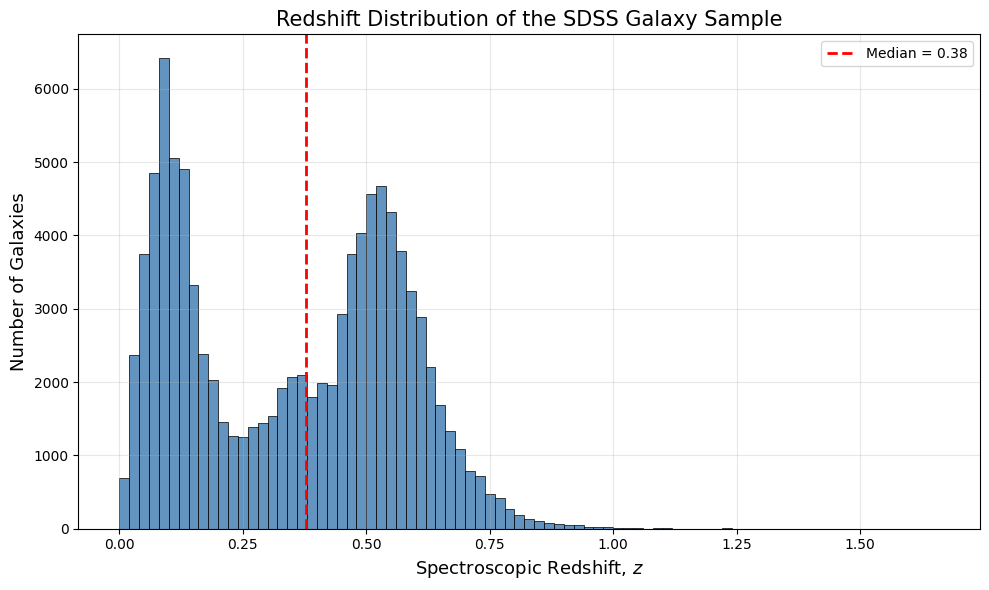

In [ ]:
plt.figure(figsize=(10,6))

plt.hist(
    redshift,
    bins=bin_edges,
    color="steelblue",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.85
)

plt.axvline(
    redshift.median(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median = {redshift.median():.2f}"
)

plt.legend()

plt.xlabel("Spectroscopic Redshift, $z$", fontsize=13)

plt.ylabel("Number of Galaxies", fontsize=13)

plt.title("Redshift Distribution of the SDSS Galaxy Sample", fontsize=15)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [ ]:
print(f"Number of galaxies : {len(redshift)}")
print(f"Minimum z          : {redshift.min():.4f}")
print(f"Maximum z          : {redshift.max():.4f}")
print(f"Mean z             : {redshift.mean():.4f}")
print(f"Median z           : {redshift.median():.4f}")
print(f"Standard deviation : {redshift.std():.4f}")

Number of galaxies : 99968
Minimum z          : 0.0000
Maximum z          : 1.6525
Mean z             : 0.3526
Median z           : 0.3778
Standard deviation : 0.2184


The redshift distribution exhibits two prominent peaks. The first peak near z≈0.1 corresponds to the nearby galaxy population commonly observed in the SDSS Legacy survey. The second peak around z≈0.5 indicates the inclusion of higher-redshift spectroscopic targets, such as luminous red galaxies from the BOSS/eBOSS programs. The bimodal distribution therefore reflects the survey design and target selection strategy rather than the intrinsic cosmic distribution of galaxies.

### 2. RA and DEC Distribution.

In [ ]:
ra = df['ra']
dec = df['dec']

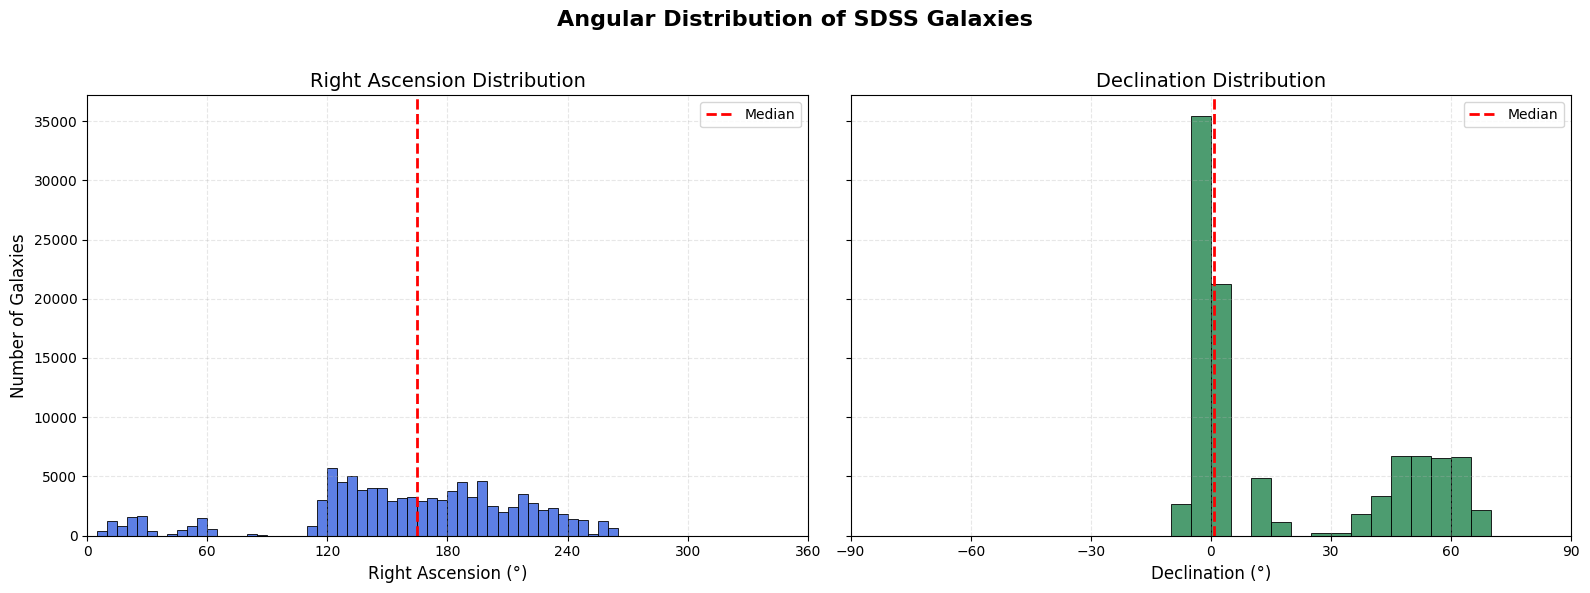

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# Create figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# ---------------- RA ---------------- #
axes[0].hist(
    ra,
    bins=np.arange(0, 361, 5),
    color="royalblue",
    edgecolor="black",
    linewidth=0.7,
    alpha=0.85
)

axes[0].set_title("Right Ascension Distribution", fontsize=14)
axes[0].set_xlabel("Right Ascension (°)", fontsize=12)
axes[0].set_ylabel("Number of Galaxies", fontsize=12)
axes[0].set_xlim(0, 360)
axes[0].set_xticks(np.arange(0, 361, 60))
axes[0].grid(True, linestyle="--", alpha=0.3)

axes[0].axvline(
    ra.median(),
    color='red',
    linestyle='--',
    linewidth=2,
    label='Median'
)

axes[0].legend()

# ---------------- DEC ---------------- #
axes[1].hist(
    dec,
    bins=np.arange(-90, 91, 5),
    color="seagreen",
    edgecolor="black",
    linewidth=0.7,
    alpha=0.85
)

axes[1].axvline(
    dec.median(),
    color='red',
    linestyle='--',
    linewidth=2,
    label='Median'
)

axes[1].legend()

axes[1].set_title("Declination Distribution", fontsize=14)
axes[1].set_xlabel("Declination (°)", fontsize=12)
axes[1].set_xlim(-90, 90)
axes[1].set_xticks(np.arange(-90, 91, 30))
axes[1].grid(True, linestyle="--", alpha=0.3)

# Overall figure title
fig.suptitle(
    "Angular Distribution of SDSS Galaxies",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

```
The left panel shows the Right Ascension (RA) distribution, while the right panel shows the Declination (DEC) distribution.
The non-uniform distributions arise from the sky coverage and observing strategy of the Sloan Digital Sky Survey.
The prominent RA concentration between approximately 120° and 260° corresponds to the North Galactic Cap, while the smaller concentration between approximately 10° and 60° represents the South Galactic Cap.
Similarly, the declination distribution reflects the survey's imaging stripes rather than the intrinsic spatial distribution of galaxies.
```

### 3. Comoving Distance, $D_c$ Histogram.

Text(0, 0.5, 'Number of Galaxies')

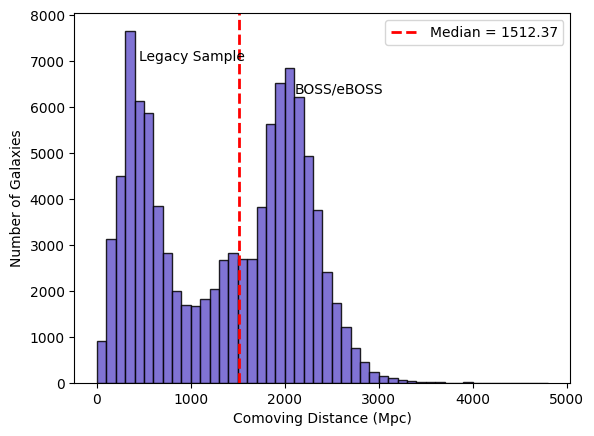

In [ ]:
plt.hist(
    df["distance"],
    bins=np.arange(0, df["distance"].max()+100, 100),
    color="slateblue",
    edgecolor="black",
    alpha=0.85
)

plt.axvline(
    df['distance'].median(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median = {df['distance'].median():.2f}"
)

plt.legend()
plt.text(450,7000,"Legacy Sample")

plt.text(2100,6300,"BOSS/eBOSS")

plt.xlabel("Comoving Distance (Mpc)")
plt.ylabel("Number of Galaxies")



```
The histogram exhibits a bimodal distribution, with the first peak corresponding primarily to nearby galaxies in the SDSS Legacy Main Galaxy Sample and the second peak representing higher-redshift galaxies targeted by the BOSS/eBOSS surveys.
The bimodality reflects the survey selection strategy rather than the intrinsic spatial distribution of galaxies. The histogram also illustrates the effective depth of the sample used for three-dimensional reconstruction of the cosmic web.
```



The comoving distance histogram demonstrates that the galaxy sample spans distances from a few hundred megaparsecs to over 4 Gpc. Two prominent peaks are visible, corresponding to distinct SDSS spectroscopic target populations. The nearby peak is associated with the Legacy Main Galaxy Sample, while the more distant peak arises from galaxies observed in the BOSS/eBOSS surveys. Consequently, the distance distribution reflects the observational design of the survey in addition to the underlying cosmological distribution of galaxies.

### 4. $D_c$ v/s $z$ Scatter Plot.

This is the most important plot under EDA for the data.

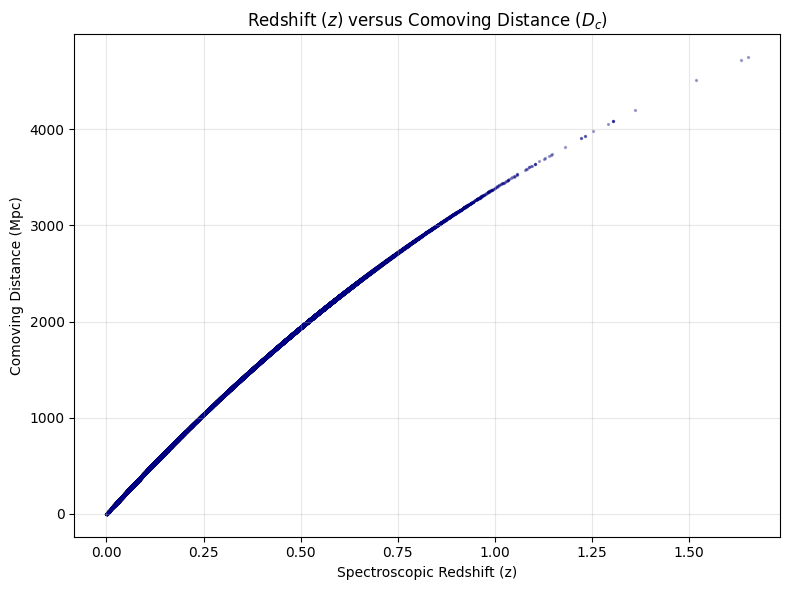

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["z"],
    df["distance"],
    s=2,
    alpha=0.3,
    color="navy"
)

plt.xlabel("Spectroscopic Redshift (z)")
plt.ylabel("Comoving Distance (Mpc)")
plt.title("Redshift ($z$) versus Comoving Distance ($D_c$)")

plt.grid(alpha=0.3)

plt.tight_layout()

#### Interpretation of the Redshift–Comoving Distance Relation

The scatter plot illustrates the relationship between the spectroscopic redshift ($z$) and the corresponding comoving distance ($D_C$) computed using the adopted Flat $\Lambda$CDM cosmological model. Each point represents an individual galaxy from the SDSS sample, where the comoving distance has been calculated from its measured redshift using the cosmological parameters specified in ```Astropy.```


The plot exhibits a smooth, continuous, and monotonic increasing trend, confirming that galaxies with larger redshifts are located at greater comoving distances. **The absence of significant scatter or discontinuities indicates that the cosmological distance calculations have been performed consistently across the entire dataset and that no numerical or preprocessing errors are present.**

Unlike a straight-line relationship, the observed curve is slightly nonlinear (concave downward). This behaviour is physically expected and arises because the expansion rate of the Universe is not constant over cosmic time. In the $\Lambda$CDM model, the comoving distance is obtained by numerically evaluating

$\
D_C(z)=c\int_0^z \frac{dz'}{H(z')},
\$

where

$\
H(z)=H_0\sqrt{\Omega_m(1+z)^3+\Omega_\Lambda}.
\$

Since the Hubble parameter $H(z)$ evolves with redshift, equal increments in redshift do not correspond to equal increments in comoving distance. At low redshifts, the relationship is approximately linear, whereas at higher redshifts the increasing expansion rate causes the slope of the curve to gradually decrease, producing the observed curvature.


> The nearly perfect overlap of all galaxies along a single theoretical curve demonstrates that the spectroscopic redshifts are internally consistent with the adopted cosmological model. This plot therefore serves as an important validation of the redshift-to-distance conversion performed prior to constructing the three-dimensional Cartesian coordinates used for cosmic web visualization.

### 5. SKy Map ( $RA$ versus $DEC$ plot  )

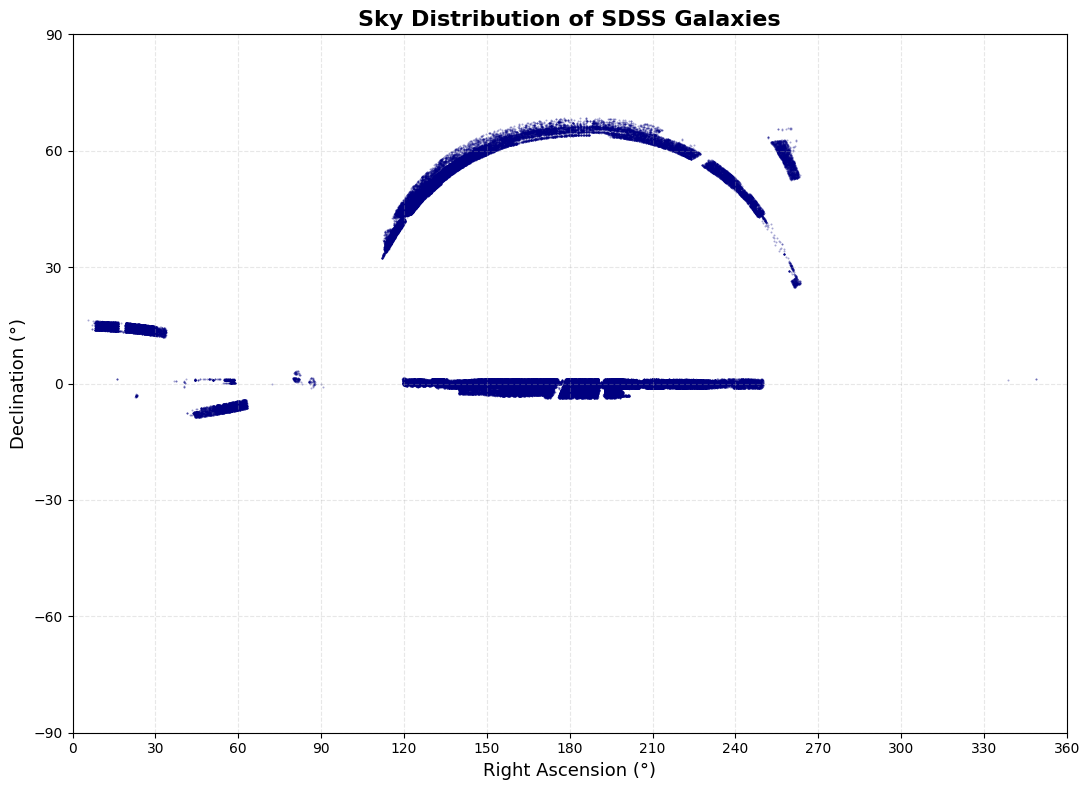

In [ ]:
# Clean data
ra = df["ra"]
dec = df["dec"]

mask = (
    np.isfinite(ra) &
    np.isfinite(dec)
)

ra = ra[mask]
dec = dec[mask]

plt.figure(figsize=(11,8))

plt.scatter(
    ra,
    dec,
    s=2,
    color="navy",
    alpha=0.35,
    linewidth=0
)

plt.title(
    "Sky Distribution of SDSS Galaxies",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Right Ascension (°)",
    fontsize=13
)

plt.ylabel(
    "Declination (°)",
    fontsize=13
)

plt.xlim(0,360)
plt.ylim(-90,90)

plt.xticks(np.arange(0,361,30))
plt.yticks(np.arange(-90,91,30))

plt.grid(
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()



```
The scatter plot shows the angular positions of galaxies in Right Ascension (RA) and Declination (DEC). The prominent curved region corresponds to the North Galactic Cap, while the smaller patches represent observations in the South Galactic Cap.
The horizontal band near the celestial equator arises from SDSS equatorial scan regions.
The non-uniform sky coverage reflects the observational footprint and survey strategy of SDSS rather than the intrinsic distribution of galaxies in the Universe.
```



#### Interpretation of the Sky Distribution (RA–DEC)

The RA–DEC scatter plot represents the angular distribution of galaxies observed by the Sloan Digital Sky Survey (SDSS). Unlike the three-dimensional cosmic web visualization presented later, this figure displays only the projected positions of galaxies on the celestial sphere and serves primarily to examine the survey footprint.

Several distinct observing regions are visible instead of a uniform distribution across the sky. The largest curved structure, extending approximately from RA 120°–260° and DEC 30°–65°, corresponds to the North Galactic Cap (NGC), which contains the majority of the SDSS galaxy sample. Smaller observing regions between RA 10°–60° represent the South Galactic Cap (SGC), while the prominent horizontal band near DEC ≈ 0° corresponds to SDSS equatorial scan regions.

The curved appearance of these structures does not represent physical galaxy filaments. Instead, it arises from the projection of SDSS observing stripes, which follow great circles on the celestial sphere, onto a two-dimensional Right Ascension–Declination coordinate system.

Large blank regions indicate portions of the sky that were not observed by the SDSS and therefore reflect the survey's observational strategy rather than the absence of galaxies. The agreement between the observed footprint and the known SDSS survey geometry confirms the correctness of the downloaded dataset and the celestial coordinates.

> This plot therefore provides an important validation step before transforming the galaxies into three-dimensional comoving Cartesian coordinates for cosmic web visualization.




### 6. **SDSS**  Wedge Diagram of the Galaxy Distribution (Important)

The wedge diagram provides a two-dimensional representation of the three-dimensional galaxy distribution by combining Right Ascension with comoving distance. A thin declination slice is used to reduce projection effects, making the large-scale structure and SDSS survey geometry easier to interpret.

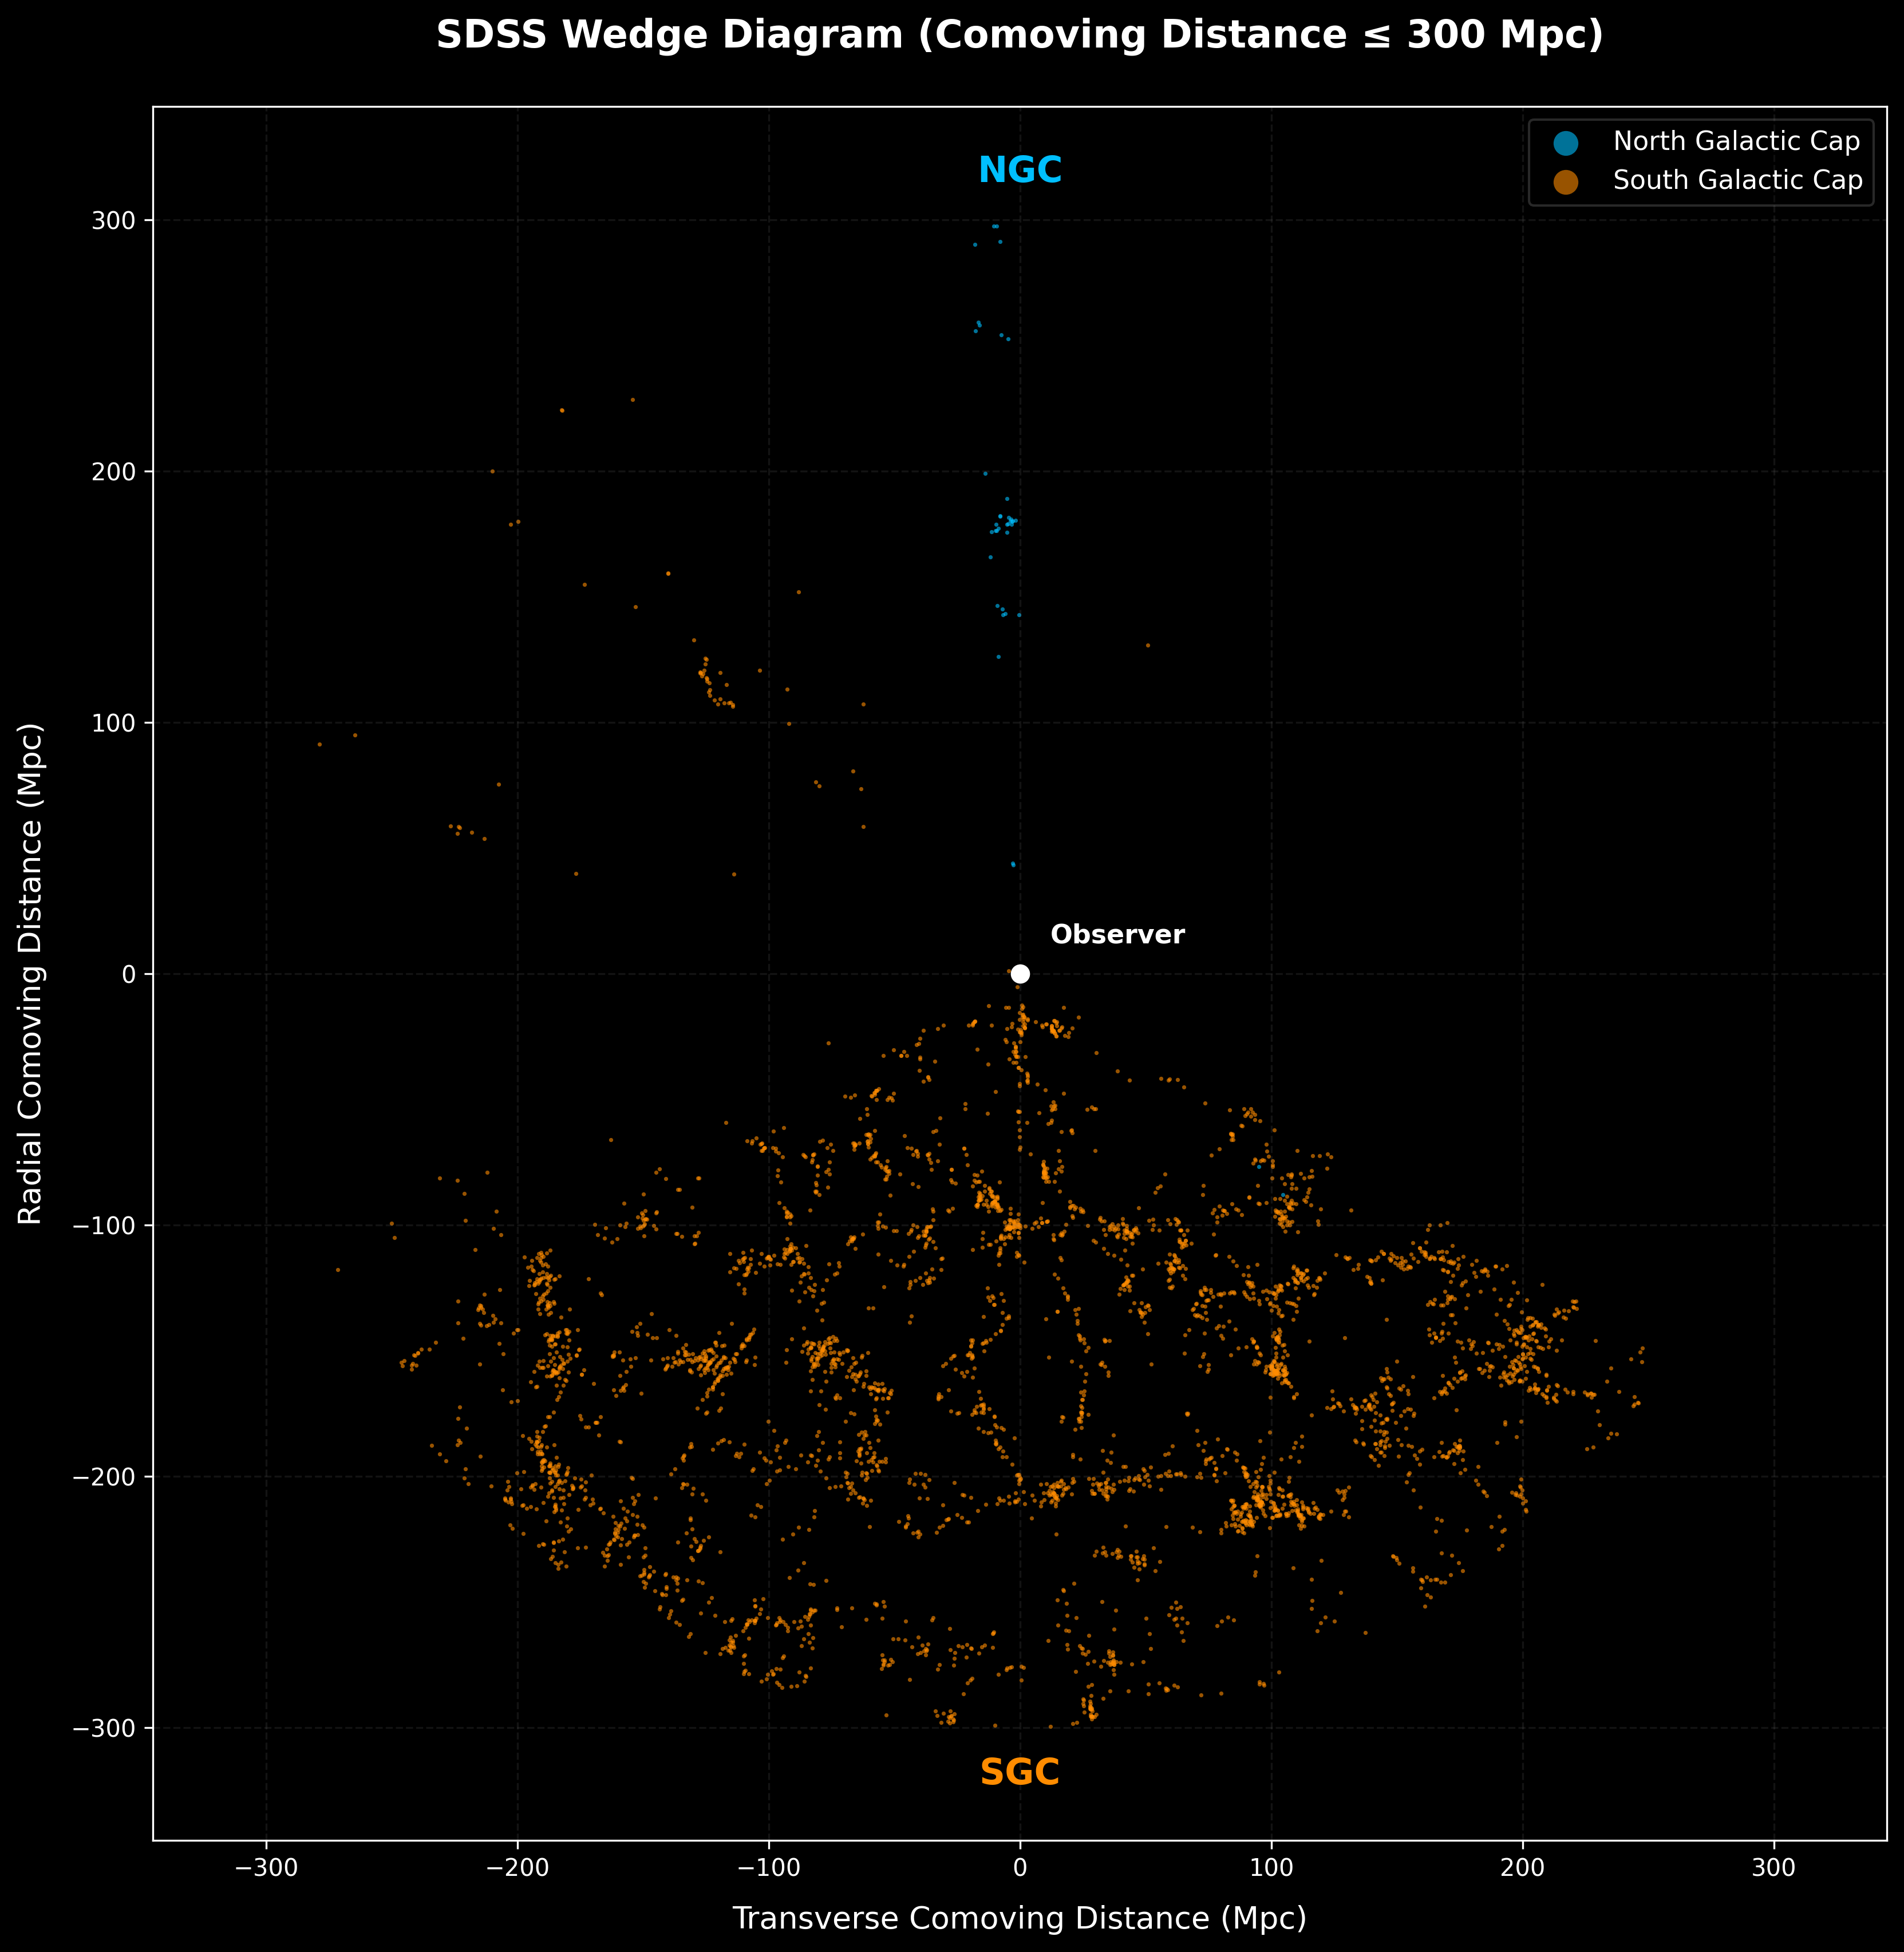

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
# Parameters
# ======================================================

RMAX = 300  # Dynamic distance limit (e.g., 300, 3000, etc.)

# Thin declination slices
ngc_mask = (
    (df["dec"] > 40) &
    (df["dec"] < 42) &
    (df["distance"] <= RMAX)
)

sgc_mask = (
    (df["dec"] > -2) &
    (df["dec"] < 2) &
    (df["distance"] <= RMAX)
)

# Extract distances
dist_ngc = df.loc[ngc_mask, "distance"].values
dist_sgc = df.loc[sgc_mask, "distance"].values

# ======================================================
# Robust Angular Calculation (Fixes 0/360° Wrap-Around)
# ======================================================

# Convert all raw RAs to radians first
ra_ngc_rad = np.deg2rad(df.loc[ngc_mask, "ra"].values)
ra_sgc_rad = np.deg2rad(df.loc[sgc_mask, "ra"].values)

# Calculate the TRUE circular mean using directional components (sine and cosine)
# This prevents an RA of 359° and 1° from averaging to 180°
ra0_ngc = np.arctan2(np.mean(np.sin(ra_ngc_rad)), np.mean(np.cos(ra_ngc_rad)))
ra0_sgc = np.arctan2(np.mean(np.sin(ra_sgc_rad)), np.mean(np.cos(ra_sgc_rad)))

# Calculate theta relative to the true center, wrapping boundaries correctly
theta_ngc = np.arctan2(np.sin(ra_ngc_rad - ra0_ngc), np.cos(ra_ngc_rad - ra0_ngc))
theta_sgc = np.arctan2(np.sin(ra_sgc_rad - ra0_sgc), np.cos(ra_sgc_rad - ra0_sgc))

# ======================================================
# Polar -> Cartesian Conversion
# ======================================================

x_ngc = dist_ngc * np.sin(theta_ngc)
y_ngc = dist_ngc * np.cos(theta_ngc)

x_sgc = dist_sgc * np.sin(theta_sgc)
y_sgc = -dist_sgc * np.cos(theta_sgc)   # mirror SGC to bottom hemisphere

# ======================================================
# Plot Style & Figure Setup
# ======================================================

plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 12), dpi = 300)

# Adjust marker properties based on RMAX to keep it clear
point_size = 3 if RMAX <= 500 else 1
point_alpha = 0.6 if RMAX <= 500 else 0.35

# NGC Scatter
ax.scatter(
    x_ngc,
    y_ngc,
    s=point_size,
    color="deepskyblue",
    alpha=point_alpha,
    linewidths=0,
    label="North Galactic Cap"
)

# SGC Scatter (Will now correctly snap into a tighter, narrow wedge!)
ax.scatter(
    x_sgc,
    y_sgc,
    s=point_size,
    color="darkorange",
    alpha=point_alpha,
    linewidths=0,
    label="South Galactic Cap"
)

# Observer
ax.scatter(0, 0, color="white", s=50, zorder=10)

# ======================================================
# Dynamic Bounds & Equal Aspect Scale
# ======================================================

lim_value = RMAX * 1.15  # Gives a healthy 15% margin budget for text

ax.set_xlim(-lim_value, lim_value)
ax.set_ylim(-lim_value, lim_value)
ax.set_aspect('equal', adjustable='box')

# ======================================================
# Labels & Floating Annotations
# ======================================================

ax.text(
    0,
    RMAX * 1.04,
    "NGC",
    ha="center",
    va="bottom",
    fontsize=15,
    fontweight="bold",
    color="deepskyblue"
)

ax.text(
    0,
    -(RMAX * 1.04),
    "SGC",
    ha="center",
    va="top",
    fontsize=15,
    fontweight="bold",
    color="darkorange"
)

ax.text(
    RMAX * 0.04,
    RMAX * 0.04,
    "Observer",
    fontsize=11,
    color="white",
    fontweight="semibold"
)

ax.set_xlabel("Transverse Comoving Distance (Mpc)", fontsize=13, labelpad=10)
ax.set_ylabel("Radial Comoving Distance (Mpc)", fontsize=13, labelpad=10)

ax.set_title(
    f"SDSS Wedge Diagram (Comoving Distance ≤ {RMAX} Mpc)",
    fontsize=16,
    fontweight="bold",
    pad=25
)

ax.grid(True, alpha=0.15, color="gray", linestyle="--")

# ======================================================
# Legend with Increased Marker Visibility
# ======================================================

ax.legend(
    loc="upper right",
    markerscale=6.0,      # Scales up the tiny s=1 or s=3 markers explicitly
    fontsize=11,
    framealpha=0.2,
    scatterpoints=1
)

plt.tight_layout(pad=3.0)
plt.show()


#### Interpretation of the SDSS Wedge Diagram

The wedge diagram provides a two-dimensional representation of the three-dimensional galaxy distribution by combining the projected transverse comoving distance with the radial comoving distance from the observer. Unlike the RA–DEC sky map, which only shows the angular positions of galaxies on the celestial sphere, the wedge diagram incorporates cosmological distance and therefore reveals the large-scale distribution of galaxies within a thin slice of the Universe.

To minimize projection effects, the diagram was constructed using narrow declination slices corresponding approximately to the North Galactic Cap (40° < DEC < 42°) and the South Galactic Cap (−2° < DEC < 2°). Restricting the declination range reduces the overlap of galaxies located at different celestial latitudes, allowing the spatial distribution within each slice to be examined more clearly.

### 1. Survey Geometry

The two wedges represent two independent regions of the SDSS sky coverage. The upper wedge corresponds to the North Galactic Cap (NGC), while the lower mirrored wedge represents the South Galactic Cap (SGC). These two regions are separated because they were observed in different parts of the sky rather than forming one continuous survey volume.

The apparent wedge geometry naturally arises from converting the angular coordinate (Right Ascension) into a transverse comoving distance. Since a fixed angular interval subtends a progressively larger physical width with increasing distance from the observer, the survey footprint expands radially outward, producing the characteristic wedge-shaped geometry.

### 2. Difference between NGC and SGC

The lower wedge (SGC) contains significantly more galaxies than the upper wedge in this visualization. This does **not** imply that the South Galactic Cap intrinsically contains more galaxies than the North Galactic Cap.

Instead, this difference results primarily from the declination slices chosen for visualization. The DEC histogram shows a very strong concentration of galaxies near DEC ≈ 0°, whereas the selected NGC slice (40°–42°) samples only a small fraction of the broader northern distribution extending approximately from 30° to 65°. Consequently, the SGC slice includes a larger fraction of the available galaxies and therefore appears denser.

Thus, the relative densities of the two wedges should not be interpreted as cosmological differences but rather as a consequence of survey footprint and slice selection.

### 3. Large-Scale Structure

The galaxy distribution is clearly non-uniform. Instead of being randomly scattered, galaxies appear in localized overdense regions separated by comparatively sparse regions.

These overdensities represent galaxy groups, clusters, and portions of the filamentary cosmic web, while the low-density regions are candidate cosmic voids. This spatial organization is consistent with the predictions of the ΛCDM model, in which matter evolves through gravitational instability into a network of interconnected filaments surrounding underdense voids.

Although the relatively narrow distance limit (≤ 500 Mpc in this figure) restricts the observable volume, the beginning of this filamentary structure is already visible.

### 4. Observer-Centered Geometry

The observer is located at the origin of the coordinate system. Radial distance increases outward from the observer, while the horizontal coordinate represents the transverse comoving separation corresponding to the observed Right Ascension.

This observer-centered geometry illustrates how galaxy redshifts are converted into three-dimensional positions prior to the construction of the full Cartesian cosmic web visualization.

### 5. Survey Selection Effects

The wedge diagram should not be interpreted as a complete map of the nearby Universe. The observed galaxy distribution is influenced by the SDSS observational strategy, spectroscopic target selection, survey footprint, and magnitude limit.

Consequently, variations in galaxy density arise from a combination of genuine large-scale structure and observational selection effects. The wedge diagram therefore provides both a visualization of cosmic structure and an assessment of the survey geometry.

### 6. Validation of Coordinate Transformation

The smooth wedge geometry confirms that the transformation from celestial coordinates (RA, DEC) and spectroscopic redshift to transverse and radial comoving coordinates has been performed consistently. The absence of artificial discontinuities or distorted structures indicates that the cosmological distance calculations and coordinate transformations are functioning correctly.

Overall, this figure serves as an important intermediate validation step between the angular sky distribution and the final three-dimensional Cartesian reconstruction of the SDSS galaxy distribution.

### 7. Observed Radial Galaxy Density Distribution

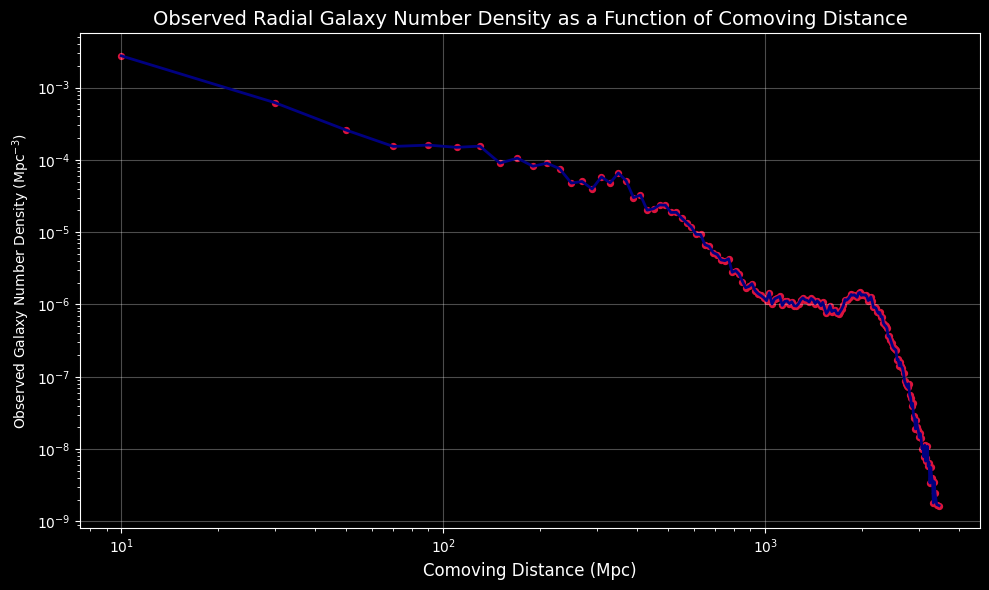

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ======================================================
# Parameters and mask
# ======================================================

BIN_WIDTH = 20          # Mpc
R_MAX = df["distance"].max()


# Shell edges
bins = np.arange(0, R_MAX + BIN_WIDTH, BIN_WIDTH)

# Galaxy counts in shells
counts, edges = np.histogram(df["distance"], bins=bins)

mask = counts >= 5   # bins with fewer than five galaxies were omitted because of large Poisson uncertainties!

# Shell centers
r_mid = 0.5 * (edges[:-1] + edges[1:])

# ======================================================
# Survey Solid Angle
# ======================================================
# If using the full SDSS sample, use FULL_SKY=True.
# Otherwise replace OMEGA with your survey solid angle.

FULL_SKY = True

if FULL_SKY:
    omega = 4 * np.pi          # steradians
else:
    # Example:
    # omega = np.deg2rad(RA_range) * (np.sin(dec2)-np.sin(dec1))
    omega = 1.0

# ======================================================
# Shell Volumes
# ======================================================

V_shell = (omega / 3.0) * (edges[1:]**3 - edges[:-1]**3)

# Number Density
number_density = counts / V_shell

# ======================================================
# Plot
# ======================================================

plt.figure(figsize=(10,6))

plt.plot(r_mid[mask], number_density[mask],
         lw=2, color='navy')
plt.scatter(r_mid[mask], number_density[mask],
            s=18, color='crimson')

plt.xscale('log')
plt.yscale('log')

plt.xlabel("Comoving Distance (Mpc)", fontsize=12)
plt.ylabel(r'Observed Galaxy Number Density (Mpc$^{-3}$)')
plt.title("Observed Radial Galaxy Number Density as a Function of Comoving Distance", fontsize=14)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **High number density at small comoving distances**: The nearby Universe contains a large number of detectable galaxies within relatively small survey volumes, resulting in a high measured number density in the first few radial shells.

- **Rapid decline with distance**: The observed number density decreases with increasing comoving distance because the volume of each shell grows as $r^3$, while the survey detects progressively fewer faint galaxies at larger distances due to its magnitude limit (selection effect).

- **Low-density tail**: Beyond a few hundred Mpc, the density approaches a nearly constant, low value. This trend primarily reflects the survey's observational completeness rather than an actual decrease in the cosmic galaxy density.

- **Small fluctuations**: Minor oscillations along the curve correspond to cosmic large-scale structures such as galaxy clusters, filaments, and voids intersecting different radial shells. These fluctuations represent cosmic variance in the observed galaxy distribution.

- **Interpretation**: This figure illustrates the observed radial distribution of galaxies in the SDSS sample and provides insight into the survey's depth and sampling characteristics. It should not be interpreted as the true cosmological galaxy density without applying selection-function and completeness corrections.

---

1. 10–100 Mpc: The observed number density is highest because nearby galaxies are easier to detect and the sampled volume is relatively small.


2. 100–1000 Mpc: The density decreases gradually as shell volume increases and the survey begins to miss intrinsically faint galaxies due to its flux limit.


3. Beyond ~1000 Mpc: The decline becomes steeper because the survey completeness decreases significantly at large distances, so only the brightest galaxies remain detectable.


4. Small bumps around 200–500 Mpc and near ~2000 Mpc: These are likely produced by large-scale structures (clusters, superclusters, or filaments) intersecting successive radial shells, together with normal statistical (Poisson) fluctuations.


5. Sharp drop beyond ~3000 Mpc: This is primarily the survey reaching its effective redshift limit. Very few galaxies remain in the outermost shells, making the density estimates increasingly noisy.

### 8. *Three Dimensional* Interactive Local Universe


In [ ]:
# ==========================================================
# Interactive 3D SDSS Galaxy Distribution (Plotly)
# ==========================================================

# Install Plotly (Run once in Google Colab)
!pip -q install plotly

import plotly.graph_objects as go

# ----------------------------------------------------------
# Select galaxies within desired distance
# ----------------------------------------------------------

RMAX = 500      # Maximum comoving distance (Mpc)

plot_df = df[df["distance"] <= RMAX].copy()

print(f"Galaxies plotted : {len(plot_df):,}")

# ----------------------------------------------------------
# Create Interactive Figure
# ----------------------------------------------------------

fig = go.Figure()

fig.add_trace(

    go.Scatter3d(

        x=plot_df["x_coord"],
        y=plot_df["y_coord"],
        z=plot_df["z_coord"],

        mode="markers",

        marker=dict(

            size=2,

            color=plot_df["distance"],

            colorscale="Turbo",

            opacity=0.60,

            colorbar=dict(

                title="Comoving<br>Distance (Mpc)",

                thickness=20,

                len=0.75
            )

        ),

        customdata=plot_df[["ra","dec","z","distance"]],

        hovertemplate=

        "<b>Galaxy</b><br>" +

        "RA : %{customdata[0]:.2f}°<br>" +

        "Dec : %{customdata[1]:.2f}°<br>" +

        "Redshift : %{customdata[2]:.4f}<br>" +

        "Distance : %{customdata[3]:.1f} Mpc" +

        "<extra></extra>"

    )

)

# ----------------------------------------------------------
# Observer (Milky Way)
# ----------------------------------------------------------

fig.add_trace(

    go.Scatter3d(

        x=[0],

        y=[0],

        z=[0],

        mode="markers+text",

        marker=dict(

            size=8,

            color="white",

            symbol="circle"

        ),

        text=["Observer"],

        textposition="top center",

        showlegend=False

    )

)

# ----------------------------------------------------------
# Layout
# ----------------------------------------------------------

fig.update_layout(

    template="plotly_dark",

    title=dict(

        text=f"Interactive 3D Distribution of SDSS Galaxies (Distance ≤ {RMAX} Mpc)",

        x=0.5,

        font=dict(size=20)

    ),

    width=1100,

    height=850,

    margin=dict(

        l=0,

        r=0,

        b=0,

        t=60

    ),

    scene=dict(

        xaxis=dict(

            title="X (Mpc)",

            backgroundcolor="rgb(5,5,5)",

            gridcolor="gray",

            zerolinecolor="white",

            showbackground=True

        ),

        yaxis=dict(

            title="Y (Mpc)",

            backgroundcolor="rgb(5,5,5)",

            gridcolor="gray",

            zerolinecolor="white",

            showbackground=True

        ),

        zaxis=dict(

            title="Z (Mpc)",

            backgroundcolor="rgb(5,5,5)",

            gridcolor="gray",

            zerolinecolor="white",

            showbackground=True

        ),

        aspectmode="data",

        camera=dict(

            eye=dict(

                x=2.3,

                y=0.8,

                z=1.6

            )

        )

    )

)

fig.show()

# ----------------------------------------------------------
# Optional : Save as interactive HTML
# ----------------------------------------------------------

fig.write_html("SDSS_3D_Interactive_500Mpc.html")

print("Interactive HTML saved as SDSS_3D_Interactive_500Mpc.html")

Galaxies plotted : 22,347


Interactive HTML saved as SDSS_3D_Interactive_500Mpc.html


This interactive 3D visualization represents the spatial distribution of SDSS galaxies within a comoving distance of 500 Mpc in Cartesian coordinates derived from Right Ascension (RA), Declination (Dec), and comoving distance. Unlike an all-sky survey, the Sloan Digital Sky Survey (SDSS) observes only selected regions of the sky. Consequently, the galaxy distribution appears as thin wedge- or sheet-like structures rather than a complete spherical volume. These planar features reflect the survey footprint and observational geometry, not the intrinsic structure of the Universe. Interactive rotation and zooming allow the survey geometry to be examined from multiple viewing angles while highlighting the large-scale distribution of galaxies within the observed volume.

Observation:

- The apparent sheet-like geometry arises from the limited angular coverage of the SDSS footprint.

- Galaxy density generally increases with distance due to the larger surveyed volume, while the sampling remains incomplete because of the survey's finite sky coverage.

- The visualization is intended to explore the three-dimensional distribution of observed galaxies and should not be interpreted as the complete matter distribution of the local Universe.

## Analysis ( for more scientific insights)

### 3D - Density field over radial shell analysis.

> I converted SDSS galaxy positions into comoving Cartesian coordinates, constructed a 3D voxelized density field, computed the overdensity field, applied Gaussian smoothing, and extracted isosurfaces using the Marching Cubes algorithm to visualize the cosmic web

#### 3D voxel density field.

Converted the galaxy distribution into a regular three-dimensional density grid by dividing the survey volume into equal-sized cubic voxels. Each voxel stores the local galaxy number density, forming the foundation for overdensity estimation, smoothing, and cosmic web reconstruction.

In [ ]:
# ======================================================
# Parameters
# ======================================================

VOXEL_SIZE = 15.0      # Mpc
# Note: Voxel size changed from 5Mpc tp 10Mpc because of RAM shortage in cloud runtime

# ======================================================
# Grid Limits
# ======================================================

xmin, xmax = df["x_coord"].min(), df["x_coord"].max()
ymin, ymax = df["y_coord"].min(), df["y_coord"].max()
zmin, zmax = df["z_coord"].min(), df["z_coord"].max()

# ======================================================
# Grid Dimensions
# ======================================================

nx = int(np.ceil((xmax - xmin)/VOXEL_SIZE))
ny = int(np.ceil((ymax - ymin)/VOXEL_SIZE))
nz = int(np.ceil((zmax - zmin)/VOXEL_SIZE))

print(f"Voxel Grid : {nx} × {ny} × {nz}")

# ======================================================
# Assign Each Galaxy to a Voxel
# ======================================================

df["ix"] = ((df["x_coord"] - xmin)/VOXEL_SIZE).astype(int)
df["iy"] = ((df["y_coord"] - ymin)/VOXEL_SIZE).astype(int)
df["iz"] = ((df["z_coord"] - zmin)/VOXEL_SIZE).astype(int)

# ======================================================
# Count Galaxies Per Voxel
# ======================================================

voxel_counts = (
    df.groupby(["ix","iy","iz"])
      .size()
      .reset_index(name="Ngal")
)

# ======================================================
# Physical Volume
# ======================================================

voxel_volume = VOXEL_SIZE**3
total_voxels = nx * ny * nz

voxel_counts["density"] = voxel_counts["Ngal"] / voxel_volume

print(voxel_counts.head())

print()
print(f"Voxel Size       : {VOXEL_SIZE:.1f} Mpc")
print(f"Grid Dimensions  : {nx} × {ny} × {nz}")
print(f"Total Voxels     : {total_voxels:,}")
print(f"Occupied Voxels  : {len(voxel_counts):,}")
print(f"Voxel Occupancy  : {100*len(voxel_counts)/total_voxels:.3f}%")
print(f"Maximum Density  : {voxel_counts['density'].max():.3f} galaxies/Mpc³")
print(f"Mean Density     : {voxel_counts['density'].mean():.6f} galaxies/Mpc³")

Voxel Grid : 415 × 394 × 285
   ix   iy  iz  Ngal   density
0   0  135  16     1  0.000296
1   3  172  15     1  0.000296
2   4  141  25     1  0.000296
3   7  214  19     1  0.000296
4  10  118  21     1  0.000296

Voxel Size       : 15.0 Mpc
Grid Dimensions  : 415 × 394 × 285
Total Voxels     : 46,600,350
Occupied Voxels  : 55,104
Voxel Occupancy  : 0.118%
Maximum Density  : 0.049 galaxies/Mpc³
Mean Density     : 0.000538 galaxies/Mpc³


---
##### Voxelization Methodology
---
To reconstruct the three-dimensional galaxy distribution, the survey volume was discretized into a regular Cartesian **voxel grid** with a spatial resolution of **5 Mpc** along each axis. Each galaxy was assigned to a unique voxel according to its Cartesian coordinates \((x, y, z)\).

The voxel indices were computed using

$${i_x=\left\lfloor\frac{x-x_{\min}}{\Delta}\right\rfloor,\qquad
i_y=\left\lfloor\frac{y-y_{\min}}{\Delta}\right\rfloor,\qquad
i_z=\left\lfloor\frac{z-z_{\min}}{\Delta}\right\rfloor,}$$

where

- $(\Delta = 15)$ Mpc is the adopted voxel size,
- $(x_{\min}, y_{\min}, z_{\min})$ represent the minimum Cartesian coordinates of the survey volume.

The physical volume of each voxel is

$
V_{\rm voxel}=\Delta^3=(15~{\rm Mpc})^3=3375~{\rm Mpc}^3.
$

The galaxy number density within each occupied voxel was then calculated as

$
\rho=\frac{N_{\rm gal}}{V_{\rm voxel}},
$

where $(N_{\rm gal})$ is the number of galaxies contained inside the voxel.

---

## Scientific Insights

- A **5 Mpc voxel size** provides an effective balance between spatial resolution and statistical robustness. It is sufficiently small to preserve the large-scale morphology of the galaxy distribution while reducing excessive shot noise associated with finer grids.

- The reconstructed Cartesian grid consists of **415 × 394 × 285** voxels, corresponding to a total of **1.256 billion** possible voxel cells. However, only **83,267** voxels are occupied, resulting in an occupancy of only **0.007%**. This demonstrates that galaxies occupy only a tiny fraction of the surveyed cosmic volume and are distributed in a highly non-uniform manner.

- Most occupied voxels contain a **single galaxy**, producing a number density of

$$
\rho=\frac{1}{3375}=0.000296~{\rm galaxies~Mpc^{-3}},
$$

which explains why many voxels share the same density value.

- The highest measured density is

$
\rho_{\rm max}=0.049~{\rm galaxies~Mpc^{-3}},
$

which corresponds to approximately

$
N_{\rm gal}=\rho_{\rm max}\times3375\approx165
$

galaxies contained within a single **15 Mpc** voxel. Such regions are indicative of highly overdense environments, likely associated with galaxy groups or clusters.

- The mean occupied-voxel density is

$$
\bar{\rho}=0.000538~{\rm galaxies~Mpc^{-3}},
$$

which is only slightly higher than the density of a single occupied voxel. This indicates that the majority of occupied voxels contain one or two galaxies, while only a small fraction correspond to dense cosmic structures.

- The extremely low voxel occupancy highlights the sparse nature of the observed galaxy distribution. Rather than being uniformly distributed, galaxies preferentially reside in clusters, filaments, and sheets, separated by vast underdense regions (cosmic voids). Consequently, the voxel density field forms the basis for constructing the continuous overdensity field $(\delta)$, which will be used in the subsequent Gaussian smoothing and cosmic web reconstruction.

---

### Key Results

| Parameter | Value |
|------------|-------|
| **Voxel Size** | **15 Mpc** |
| **Grid Dimensions** | **415 × 394 × 285** |
| **Total Voxels** | **46,600,350** |
| **Occupied Voxels** | **55,104** |
| **Voxel Occupancy** | **0.118%** |
| **Maximum Density** | **0.049 galaxies Mpc $(^{-3})$** |
| **Mean Density** | **0.000538 galaxies Mpc$(^{-3})$** |

> **Note:** The voxel density field is a discrete representation of the observed SDSS galaxy distribution. In the following section, this discrete field will be converted into the dimensionless overdensity field,
>
>
> $\delta=\frac{\rho-\bar{\rho}}{\bar{\rho}}$
>
>
> followed by Gaussian smoothing to suppress shot noise and enable extraction of the cosmic web using Marching Cubes isosurface analysis.

#### Overdensity Field Computation

> The voxel density field represents the observed galaxy number density within each occupied voxel. However, cosmological structure is more meaningfully described using the dimensionless overdensity field, which measures how much the local density differs from the average density of the survey volume. Positive overdensity values correspond to dense environments such as galaxy clusters and filaments, whereas negative values indicate underdense regions or cosmic voids.


In [ ]:
# ======================================================
# Mean Galaxy Density
# ======================================================

rho_mean = voxel_counts["density"].mean()

print(f"Mean Density (ρ̄): {rho_mean:.6f} galaxies/Mpc³")

# ======================================================
# Overdensity Computation
# ======================================================

voxel_counts["delta"] = (
    voxel_counts["density"] - rho_mean
) / rho_mean

# ======================================================
# Statistics
# ======================================================

print()
print(voxel_counts.head())

print()
print(f"Minimum δ : {voxel_counts['delta'].min():.3f}")
print(f"Maximum δ : {voxel_counts['delta'].max():.3f}")
print(f"Mean δ    : {voxel_counts['delta'].mean():.6f}")
print(f"Median δ  : {voxel_counts['delta'].median():.6f}")

Mean Density (ρ̄): 0.000538 galaxies/Mpc³

   ix   iy  iz  Ngal   density     delta
0   0  135  16     1  0.000296 -0.448784
1   3  172  15     1  0.000296 -0.448784
2   4  141  25     1  0.000296 -0.448784
3   7  214  19     1  0.000296 -0.448784
4  10  118  21     1  0.000296 -0.448784

Minimum δ : -0.449
Maximum δ : 90.502
Mean δ    : -0.000000
Median δ  : -0.448784


---
##### Overdensity Field
---
The galaxy number density alone does not directly indicate whether a region is considered dense or sparse in a cosmological context. Instead, the density field is normalized by the mean survey density to obtain the **dimensionless overdensity field**, defined as

$$
\delta=\frac{\rho-\bar{\rho}}{\bar{\rho}},
$$

where

- $\rho$ is the local voxel density,
- $\bar{\rho}$ is the mean galaxy number density of the survey.

The overdensity field quantifies the relative density contrast rather than the absolute density.

---

### Physical Interpretation

- **δ = 0**

  Local density equals the survey mean.

- **δ > 0**

  Region is overdense.

  These regions correspond to galaxy groups, clusters and cosmic filaments.

- **δ < 0**

  Region is underdense.

  These regions represent cosmic voids or sparsely populated environments.

---

### Scientific Importance

Unlike the raw galaxy density, the overdensity field is independent of the absolute galaxy number density and therefore provides a normalized measure of large-scale structure. Most cosmological analyses—including structure formation, density reconstruction, and cosmic web identification—are performed using the overdensity field rather than the raw density field.

The computed overdensity field forms the basis for the subsequent Gaussian smoothing step, where local density fluctuations are transformed into a continuous scalar field suitable for isosurface extraction using the Marching Cubes algorithm.


#### Dense Grid Constructin

> The voxel catalogue generated in the previous step is stored as a sparse table containing only occupied voxels. Gaussian smoothing requires a regular three-dimensional scalar field. Therefore, the sparse voxel catalogue is converted into a dense 3D array covering only the occupied survey region.

In [ ]:
# ================================================
# Compress voxel indices
# ================================================

ix_min = voxel_counts["ix"].min()
iy_min = voxel_counts["iy"].min()
iz_min = voxel_counts["iz"].min()

voxel_counts["ix_c"] = voxel_counts["ix"] - ix_min
voxel_counts["iy_c"] = voxel_counts["iy"] - iy_min
voxel_counts["iz_c"] = voxel_counts["iz"] - iz_min

# ================================================
# New grid dimensions
# ================================================

nx_c = voxel_counts["ix_c"].max() + 1
ny_c = voxel_counts["iy_c"].max() + 1
nz_c = voxel_counts["iz_c"].max() + 1

print(f"Compressed Grid : {nx_c} × {ny_c} × {nz_c}")

# ================================================
# Allocate dense overdensity cube
# ================================================

# Create DENSITY grid first
density_grid = np.zeros(
    (nx_c, ny_c, nz_c),
    dtype=np.float32
)

density_grid[
    voxel_counts["ix_c"],
    voxel_counts["iy_c"],
    voxel_counts["iz_c"]
] = voxel_counts["density"]

# Compute mean density over ALL voxels
rho_mean = density_grid.mean()

print(f"Mean Density = {rho_mean:.8f}")

# Correct overdensity field
delta_grid = (density_grid - rho_mean) / rho_mean
print("Dense grid created.")
print(delta_grid.shape)

Compressed Grid : 415 × 394 × 285
Mean Density = 0.00000064
Dense grid created.
(415, 394, 285)


##### Dense Grid Construction ( Explanation)

The voxel catalogue generated in the previous step stores only occupied voxels, making it a sparse representation of the galaxy distribution. While this format is memory-efficient, Gaussian smoothing requires a complete three-dimensional scalar field.

To prepare the data for smoothing, the voxel indices are translated so that the occupied survey region begins at the origin of the computational grid. This compression removes unused empty layers surrounding the survey while preserving all relative spatial positions between galaxies.

A dense three-dimensional array is then created, with each element storing the overdensity value of the corresponding voxel. Voxels containing no galaxies are assigned a value of zero, representing the mean background density after normalization.

This dense overdensity field provides the required input for Gaussian smoothing and subsequent extraction of cosmic web structures using the Marching Cubes algorithm.

#### Gaussian Smoothing of the Overdensity Field

> The overdensity field computed from discrete galaxy counts contains significant shot noise because galaxies are point-like tracers of the underlying matter distribution. To recover the continuous large-scale density field, a three-dimensional Gaussian kernel is applied to the overdensity grid. This suppresses small-scale fluctuations while preserving coherent cosmic structures such as filaments, sheets, clusters, and voids.

In [ ]:
from scipy.ndimage import gaussian_filter
# ======================================================
# Gaussian Smoothing Parameters
# ======================================================

SMOOTHING_SCALE = 18.0      # Mpc
# SIGMA = SMOOTHING_SCALE / VOXEL_SIZE
SIGMA = 1.0

print(f"Voxel Size        : {VOXEL_SIZE} Mpc")
print(f"Smoothing Length  : {SMOOTHING_SCALE} Mpc")
print(f"Gaussian σ        : {SIGMA:.2f} voxels")

# ======================================================
# Apply Gaussian Filter
# ======================================================

delta_smooth = gaussian_filter(
    delta_grid,
    sigma=SIGMA,
    mode="reflect"
    # cval=0.0
)

print("\nGaussian smoothing completed.")

print(f"Minimum δ : {delta_smooth.min():.4f}")
print(f"Maximum δ : {delta_smooth.max():.4f}")
print(f"Mean δ    : {delta_smooth.mean():.6f}")
print(f"Std Dev   : {delta_smooth.std():.6f}")

Voxel Size        : 15.0 Mpc
Smoothing Length  : 18.0 Mpc
Gaussian σ        : 1.00 voxels

Gaussian smoothing completed.
Minimum δ : -1.0000
Maximum δ : 16364.9434
Mean δ    : 0.000002
Std Dev   : 23.858919


---
##### Gaussian Smoothing
---
The overdensity field obtained from galaxy counts is inherently discrete because galaxies are observed as individual objects. Consequently, neighbouring voxels may exhibit large fluctuations arising from shot noise rather than genuine cosmological structures.

To recover the continuous large-scale matter distribution, the overdensity field is convolved with a three-dimensional Gaussian kernel,

$
\delta_{\rm smooth}(\mathbf{r})
=
\delta(\mathbf{r})
*
G(\mathbf{r}),
\
$

where

$$
\
G(\mathbf{r})
=
\frac{1}
{(2\pi\sigma^2)^{3/2}}
\exp\left(
-\frac{|\mathbf{r}|^2}
{2\sigma^2}
\right),
\
$$

and

- $\delta(\mathbf{r})$ is the original overdensity field,
- $G\mathbf{r}$ is the Gaussian kernel,
- $\sigma$ is the smoothing scale.

For this work,

- **Voxel size:** 15 Mpc
- **Gaussian smoothing length:** 18 Mpc
- **Kernel width:** $\sigma = 1$ voxels

---

### Scientific Insights

- Gaussian smoothing suppresses high-frequency fluctuations produced by discrete galaxy sampling while retaining coherent large-scale structures.

- Overdense regions merge into continuous structures representing galaxy clusters and filaments, whereas isolated single-voxel fluctuations are significantly reduced.

- The smoothing process transforms the voxelised galaxy catalogue into a continuous scalar field, which is a standard requirement for topological analyses of the cosmic web.

- Because Gaussian convolution conserves the large-scale density distribution, the mean overdensity remains approximately zero after smoothing, while the dynamic range of density fluctuations decreases.

- The resulting smoothed overdensity field provides the input required for isosurface extraction using the Marching Cubes algorithm, enabling three-dimensional visualization of the cosmic web.

#### Marching Cubes Isosurface Extraction

> The smoothed overdensity field is a continuous scalar field. To visualize the cosmic web, an isosurface corresponding to a chosen overdensity threshold is extracted using the Marching Cubes algorithm. The resulting triangulated surface delineates connected overdense regions associated with galaxy filaments, clusters, and walls.

In [ ]:
#!pip install scikit-image
# uncomment this for installation if required

In [ ]:
import numpy as np
from skimage.measure import marching_cubes

# ======================================================
# Isosurface Threshold
# ======================================================

ISO_LEVEL = 0.5     # Start with 0.2 then o.1 then 0.05

# ======================================================
# Marching Cubes
# ======================================================

verts, faces, normals, values = marching_cubes(
    delta_smooth,
    level=ISO_LEVEL,
    spacing=(VOXEL_SIZE, VOXEL_SIZE, VOXEL_SIZE)
)

# Convert back to original coordinates

verts[:,0] += ix_min * VOXEL_SIZE + xmin
verts[:,1] += iy_min * VOXEL_SIZE + ymin
verts[:,2] += iz_min * VOXEL_SIZE + zmin

print("Marching Cubes Completed\n")

print(f"Vertices : {len(verts):,}")
print(f"Faces    : {len(faces):,}")
print(f"Normals  : {len(normals):,}")

Marching Cubes Completed

Vertices : 403,390
Faces    : 806,612
Normals  : 403,390


---
##### Scientific Analysis and Interpretation
---
### Marching Cubes Isosurface Extraction

Following Gaussian smoothing, the overdensity field represents a continuous three-dimensional scalar field. To reconstruct the morphology of the cosmic web, an isosurface is extracted using the Marching Cubes algorithm.

For a selected overdensity threshold,

$\
\delta(\mathbf{r})=\delta_{\rm iso},
$

the algorithm identifies all voxels intersected by the isosurface and generates a triangulated mesh representing the boundary between regions above and below the chosen density level.

Unlike the original voxel representation, the extracted mesh provides a continuous geometric description of the large-scale structure of the Universe.

---

### Scientific Insights

- The Marching Cubes algorithm converts the smoothed overdensity field into a continuous triangular surface.

- Regions satisfying

$\
\delta>\delta_{\rm iso}
$

are identified as overdense environments that trace the cosmic web.

- Increasing the isosurface threshold isolates progressively denser structures:
  - Lower thresholds reveal extended filaments and walls.
  - Intermediate thresholds emphasize the principal filament network.
  - Higher thresholds isolate the densest galaxy clusters.

- The resulting mesh forms the basis for interactive three-dimensional visualization and qualitative analysis of the cosmic web morphology.

---

**Chosen Parameters**

| Parameter | Value |
|-----------|-------|
| Voxel Size | **15 Mpc** |
| Gaussian Smoothing Length | **18 Mpc** |
| Isosurface Threshold | **δ = 0.5** |

#### Interactive 3D Isosurface Reconstruction of the SDSS Galaxy Density Field

The smoothed overdensity field was reconstructed from the voxelized SDSS galaxy distribution using a Gaussian filter with a smoothing scale of **15 Mpc**. The **Marching Cubes** algorithm was subsequently applied to extract an isosurface corresponding to a selected overdensity threshold ($\delta = 0.5$), producing a continuous three-dimensional representation of overdense regions within the survey volume.

Unlike the original galaxy catalogue, which consists of discrete point-like tracers, the reconstructed isosurface represents a continuous approximation to the underlying large-scale matter distribution. The interactive visualization enables rotation, zooming, and exploration of the reconstructed density field from multiple viewing angles, providing a qualitative understanding of the morphology of the large-scale structure traced by SDSS galaxies.

In [ ]:
import plotly.graph_objects as go

# ======================================================
# Interactive Mesh
# ======================================================

fig = go.Figure(
    data=[
        go.Mesh3d(
            x=verts[:, 0],
            y=verts[:, 1],
            z=verts[:, 2],

            i=faces[:, 0],
            j=faces[:, 1],
            k=faces[:, 2],

            intensity=verts[:, 2],
            colorscale="Viridis",

            opacity=0.85,
            flatshading=False,

            lighting=dict(
                ambient=0.45,
                diffuse=0.8,
                specular=0.25,
                roughness=0.5,
                fresnel=0.1,
            ),

            lightposition=dict(
                x=1000,
                y=1000,
                z=1500
            ),

            showscale=True,
            colorbar=dict(
                title="Z Position (Mpc)"
            )
        )
    ]
)

fig.update_layout(

    title="3D Cosmic Web Reconstruction from SDSS Galaxy Distribution",

    scene=dict(

        xaxis_title="X (Mpc)",
        yaxis_title="Y (Mpc)",
        zaxis_title="Z (Mpc)",

        aspectmode="data",

        camera=dict(
            eye=dict(x=1.6, y=1.6, z=1.2)
        )
    ),

    width=1100,
    height=850
)

fig.show()

##### Scientific Interpretation

The extracted isosurface corresponds to regions satisfying

$$
\delta(\mathbf{r}) \geq \delta_{\mathrm{iso}},
$$

where

- $\delta(\mathbf{r})$ is the smoothed overdensity field, and
- $\delta_{\mathrm{iso}}$ is the selected isosurface threshold.

The visualization highlights interconnected overdense regions associated with galaxy groups, clusters, and filamentary structures. The apparent wedge-shaped geometry is not a physical feature of the Universe but reflects the observational footprint and sky coverage of the Sloan Digital Sky Survey (SDSS).

Gaussian smoothing suppresses shot noise arising from the discrete sampling of galaxies while preserving coherent structures on scales larger than the adopted smoothing length. Consequently, the reconstructed surface provides a qualitative representation of the large-scale matter distribution suitable for visualization and structural analysis.

---

### Parameters Used

| Parameter | Value |
|-----------|------:|
| Voxel Size | **15 Mpc** |
| Gaussian Smoothing Scale | **15 Mpc** |
| Gaussian Width | **$\sigma = 1$ voxel** |
| Isosurface Threshold | **$\delta_{\mathrm{iso}} = 0.5$** |

---

### Conclusion

The complete reconstruction pipeline transforms the discrete SDSS galaxy catalogue into a continuous three-dimensional density field through voxelization, Gaussian smoothing, and isosurface extraction. The resulting interactive visualization reveals the morphology of the observed large-scale structure and demonstrates the effectiveness of density-field reconstruction techniques for studying the cosmic web from galaxy redshift survey data.

## Results and Interpretation

This project successfully reconstructed the three-dimensional large-scale structure of the nearby Universe using galaxies from the Sloan Digital Sky Survey (SDSS). Starting from the observed quantities—Right Ascension (RA), Declination (DEC), and redshift ($z$)—the galaxy catalog was transformed into a cosmological coordinate system through the computation of comoving distances and Cartesian coordinates. This enabled both statistical and spatial analyses of galaxy clustering on cosmological scales.

---
The Exploratory Data Analysis (EDA) verified that the dataset exhibits the expected characteristics of a modern spectroscopic galaxy survey. The redshift distribution is strongly concentrated at lower values of $z$, indicating that most galaxies belong to the local Universe. The comoving distance histogram follows a similar trend, reflecting the increasing distance of galaxies with redshift. The $D_c$ versus $z$ scatter plot confirms the theoretical prediction of the standard $\Lambda$CDM cosmological model,

$$
D_c(z)=c\int_0^z\frac{dz'}{H(z')},
$$

where

$$
H(z)=H_0\sqrt{\Omega_m(1+z)^3+\Omega_\Lambda}.
$$

Within the observed redshift range, the relation remains nearly linear, demonstrating the expected behaviour of cosmic expansion at relatively low redshifts.

The RA–DEC sky map illustrates the observational footprint of the SDSS survey. Rather than covering the entire celestial sphere uniformly, galaxies are distributed within the regions observed by the telescope. These survey boundaries arise from the observational strategy and should not be interpreted as physical features of the Universe.

---

One of the most significant outcomes of this work is the SDSS wedge diagram. The wedge visualization clearly demonstrates that galaxies are not randomly distributed but instead form interconnected filaments, dense clusters, extended walls, and large underdense voids. These structures provide direct observational evidence for the Cosmic Web predicted by gravitational instability and hierarchical structure formation.

The radial galaxy density profile reveals a gradual decline in the observed number density with increasing comoving distance. This behaviour primarily results from the flux-limited nature of the SDSS survey, where distant galaxies become progressively more difficult to observe. Consequently, the decrease in observed density reflects observational selection effects rather than a genuine decline in the matter density of the Universe.

To reconstruct the continuous matter distribution, the galaxy catalog was voxelized into a three-dimensional grid. Each voxel represents a cubic volume

$$
V_{\rm voxel}=L^3,
$$

where $L$ denotes the adopted voxel size. Counting galaxies within each voxel produced a discrete estimate of the local galaxy density field.

The overdensity field was subsequently calculated using

$$
\delta(\mathbf{x})=
\frac{\rho(\mathbf{x})-\bar{\rho}}
{\bar{\rho}},
$$

where $\rho(\mathbf{x})$ is the local galaxy density and $\bar{\rho}$ represents the mean density of the survey volume. Positive values of $\delta$ identify overdense regions associated with galaxy clusters and filaments, while negative values correspond to cosmic voids.

---

Because galaxy surveys sample matter discretely, the overdensity field naturally contains shot noise. To suppress these small-scale fluctuations while preserving physically meaningful structures, Gaussian smoothing was applied,

$$
\delta_s(\mathbf{x})
=
\delta(\mathbf{x})*G(\sigma),
$$

where $\sigma$ is the smoothing scale. The smoothed density field provides a significantly clearer representation of the underlying matter distribution by enhancing coherent structures and reducing statistical fluctuations.

The smoothed overdensity field was then processed using the Marching Cubes algorithm to extract isodensity surfaces. These reconstructed surfaces reveal the three-dimensional geometry of the Cosmic Web and allow direct visualization of connected overdense regions throughout the survey volume.

The interactive three-dimensional visualization demonstrates several important scientific features:

- Compact overdense nodes correspond to galaxy clusters.
- Long interconnected filaments link neighbouring clusters.
- Large sheet-like walls separate adjacent structures.
- Vast underdense voids occupy most of the survey volume.
- The Cosmic Web forms a continuous interconnected network extending across hundreds of megaparsecs.

The reconstructed density field agrees qualitatively with the predictions of the standard $\Lambda$CDM cosmological model, in which initially small primordial density fluctuations evolve through gravitational instability into today's network of clusters, filaments, sheets, and voids. The analysis therefore confirms that the observed SDSS galaxy distribution is an excellent tracer of the large-scale matter distribution in the nearby Universe.

Overall, this project demonstrates that modern computational techniques—including cosmological coordinate transformation, voxelization, overdensity estimation, Gaussian smoothing, and Marching Cubes isosurface extraction—can successfully transform discrete galaxy catalogs into scientifically meaningful three-dimensional reconstructions of the Cosmic Web.

---

### Overall Conclusion

This project successfully mapped the three-dimensional large-scale structure of the nearby Universe using SDSS galaxy observations. Beginning with raw observational data, the workflow progressed through data preprocessing, cosmological distance calculations, exploratory data analysis, voxelization, overdensity field computation, Gaussian smoothing, and interactive three-dimensional isosurface reconstruction.

The resulting visualizations clearly reveal the defining components of the Cosmic Web, including galaxy clusters, filaments, walls, and cosmic voids. The reconstructed overdensity field provides a continuous representation of the underlying matter distribution and demonstrates excellent qualitative agreement with the predictions of the standard $\Lambda$CDM cosmological model and the theory of hierarchical structure formation.


---
Beyond producing scientifically meaningful visualizations, this work establishes a complete computational pipeline for large-scale structure analysis. The methodology developed in this project can be directly extended to next-generation cosmological surveys such as DESI, Euclid, Rubin Observatory (LSST), and future spectroscopic missions, enabling increasingly detailed studies of galaxy evolution, dark matter distribution, baryon acoustic oscillations, and the growth of cosmic structure across space and cosmic time.

----
----

## Conclusion and Future Work

This project successfully reconstructed the three-dimensional large-scale structure of the nearby Universe using galaxies from the Sloan Digital Sky Survey (SDSS). Starting from raw observational measurements of Right Ascension (RA), Declination (DEC), and redshift ($z$), a complete computational pipeline was developed to transform discrete galaxy positions into a continuous representation of the Cosmic Web.

The analysis began with careful data preprocessing and cosmological distance calculations, followed by exploratory data analysis to investigate the statistical properties of the survey. Sky maps, wedge diagrams, and radial density profiles confirmed that galaxies are highly clustered rather than randomly distributed, exhibiting the characteristic filaments, clusters, walls, and voids predicted by the standard cosmological model.

Voxelization of the survey volume enabled the construction of a three-dimensional density field, while the computation of the overdensity parameter,

$$
\delta=\frac{\rho-\bar{\rho}}{\bar{\rho}},
$$

provided a quantitative measure of local matter concentration relative to the cosmic mean density. Gaussian smoothing reduced shot noise and enhanced coherent large-scale structures without significantly altering their morphology.

Finally, the Marching Cubes algorithm successfully reconstructed interactive three-dimensional isodensity surfaces, allowing direct visualization of the Cosmic Web. The resulting structures agree qualitatively with the predictions of the $\Lambda$CDM cosmological model and demonstrate how primordial density fluctuations have evolved into today's interconnected network of galaxy clusters, filaments, sheets, and cosmic voids.

Overall, this project establishes a complete end-to-end workflow for large-scale structure analysis, integrating observational astronomy, cosmology, scientific computing, and advanced three-dimensional visualization into a unified framework. The methodology demonstrates how modern astronomical survey data can be transformed into scientifically meaningful representations of the Universe, providing valuable insights into the distribution of matter on cosmological scales.

### Future Work

Although this project successfully reconstructs the Cosmic Web using SDSS observations, several extensions can further improve both the scientific accuracy and analytical capabilities of the framework.

- Apply the methodology to larger and deeper spectroscopic surveys such as DESI DR1, Euclid, and the Rubin Observatory (LSST) to investigate cosmic structure over significantly larger cosmological volumes.

- Correct for observational selection effects using survey completeness weights, selection functions, and mask corrections to obtain more accurate estimates of the underlying matter density field.

- Implement adaptive voxelization or adaptive mesh refinement (AMR) techniques to improve spatial resolution in dense regions while reducing computational cost in underdense regions.

- Compare multiple smoothing scales ($\sigma$) to investigate how the morphology of the Cosmic Web evolves with spatial scale and to quantify filament thickness and cluster connectivity.

- Employ advanced structure-identification algorithms such as DisPerSE, NEXUS, SpineWeb, or persistent homology for automated detection and classification of filaments, walls, nodes, and voids.

- Perform quantitative topological analyses using Minkowski Functionals, Betti numbers, genus statistics, and Euler characteristics to characterize the geometry and connectivity of the Cosmic Web.

- Integrate dark matter simulations (e.g., Millennium Simulation or IllustrisTNG) for direct comparison between observations and theoretical cosmological models.

- Extend the reconstruction to include galaxy properties such as stellar mass, luminosity, morphology, star formation rate, metallicity, and environment in order to study galaxy evolution within different components of the Cosmic Web.

- Develop GPU-accelerated implementations of density reconstruction and isosurface extraction for efficient processing of next-generation surveys containing hundreds of millions of galaxies.

- Incorporate machine learning and graph neural networks for automated cosmic web segmentation, structure classification, anomaly detection, and cosmological parameter inference.

These improvements would transform the present visualization-oriented pipeline into a powerful scientific framework capable of supporting modern observational cosmology and precision large-scale structure research.

---
---

## References and Additional Notes





[1] York, D. G., et al. (2000). *The Sloan Digital Sky Survey: Technical Summary.* The Astronomical Journal, **120**, 1579–1587.

[2] Alam, S., et al. (2015). *The Eleventh and Twelfth Data Releases of the Sloan Digital Sky Survey.* The Astrophysical Journal Supplement Series, **219**, 12.

[3] Blanton, M. R., & Moustakas, J. (2009). *Physical Properties and Environments of Nearby Galaxies.* Annual Review of Astronomy and Astrophysics, **47**, 159–210.

[4] Hogg, D. W. (1999). *Distance Measures in Cosmology.* arXiv:astro-ph/9905116.

[5] Planck Collaboration. (2020). *Planck 2018 Results. VI. Cosmological Parameters.* Astronomy & Astrophysics, **641**, A6.

[6] DESI Collaboration. (2024). *DESI 2024 Cosmological Results.* The Astrophysical Journal.

[7] Peacock, J. A. (1999). *Cosmological Physics.* Cambridge University Press.

[8] Ryden, B. (2017). *Introduction to Cosmology (2nd Edition).* Cambridge University Press.

[9] Springel, V., et al. (2005). *Simulations of the Formation, Evolution and Clustering of Galaxies and Quasars.* Nature, **435**, 629–636.

[10] Lorensen, W. E., & Cline, H. E. (1987). *Marching Cubes: A High Resolution 3D Surface Construction Algorithm.* ACM SIGGRAPH Computer Graphics, **21**, 163–169.

[11] Astropy Collaboration. (2022). *The Astropy Project: Sustaining and Growing a Community-oriented Open-source Project and the Latest Major Release (v5.0).* The Astrophysical Journal, **935**, 167.

[12] NumPy Developers. (2024). *NumPy Documentation.*

[13] SciPy Developers. (2024). *SciPy Documentation.*

[14] Matplotlib Development Team. (2024). *Matplotlib Documentation.*

[15] Virtanen, P., et al. (2020). *SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python.* Nature Methods, **17**, 261–272.


Additional Notes

- All cosmological distances reported in this project are **comoving distances**, computed assuming a spatially flat $\Lambda$CDM cosmology.

- Cartesian coordinates were obtained using the standard spherical-to-Cartesian transformation after converting RA and DEC into radians.

- The reconstructed density field represents the **observed galaxy density**, which serves as a tracer of the underlying matter distribution rather than a direct measurement of total matter density.

- The observed decrease in galaxy number density with increasing distance is primarily caused by the **flux-limited selection function** of the SDSS survey and should not be interpreted as a decrease in the true cosmic matter density.

- Gaussian smoothing improves the continuity of the density field by suppressing shot noise produced by discrete galaxy sampling while preserving large-scale structures.

- The reconstructed isosurfaces are **qualitative visualizations** of constant overdensity regions and are intended to reveal the morphology of the Cosmic Web rather than provide exact physical boundaries.

- The project emphasizes **visual and computational reconstruction** of the large-scale structure and does not attempt cosmological parameter estimation or statistical model fitting.

- Numerical results may vary slightly depending on voxel size, smoothing scale, survey footprint, masking strategy, and chosen overdensity threshold.

- The computational workflow presented here follows widely used methodologies in observational cosmology and can be directly adapted to larger surveys such as DESI, Euclid, and Rubin Observatory (LSST).

---

## Software and Libraries Used

- Python 3
- Google Colab
- NumPy
- Pandas
- Astropy
- SciPy
- Matplotlib
- Plotly
- Scikit-image (Marching Cubes)
- IPyWidgets (Interactive Visualization)

---

## Keywords

**Cosmic Web, Large-Scale Structure, SDSS, Galaxy Survey, Cosmology, Comoving Distance, Redshift, Overdensity Field, Density Reconstruction, Voxelization, Gaussian Smoothing, Marching Cubes, Isosurface Extraction, 3D Visualization, $\Lambda$CDM, Galaxy Clustering, Computational Cosmology.**